# Analyse des expéditions (`shipments`) : exploration, patterns et anomalies

**Contexte.** Ce notebook étudie la table `shipments.csv` (expéditions logistiques d'un ERP : expéditeur, destinataire, sites d'origine et de destination, transporteur, catégorie d'article, quantité, température, autorisation, motif déclaré, statut). L'objectif est de comprendre la structure des données, puis de repérer des **comportements inhabituels** : combinaisons rares mais cohérentes (*patterns*) et lignes statistiquement atypiques (*anomalies*).


---
## 0. Configuration

### 0.1 Imports et modules utilitaires

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

project_root = next(
	(path for path in [Path.cwd(), *Path.cwd().parents]
	 if (path / "utils").is_dir()),
	Path.cwd(),
)
if str(project_root) not in sys.path:
	sys.path.insert(0, str(project_root))

from utils.clean_csv import clean_csv
from utils.variable_analysis import analyser_variables, tracer_histogrammes
from utils.correlation_matrices import tracer_matrices
from utils.pattern_detection import lire_csv, enrichir, detecter_patterns, profiler_groupe, masque_itemset
from utils.anomaly_detection import detecter_anomalies



**Rapport.** Les modules du dossier `utils` couvrent chaque étape : `clean_csv` (nettoyage), `variable_analysis` (histogrammes et statistiques), `correlation_matrices` (Spearman / V de Cramér), `pattern_detection` (itemsets fréquents) et `anomaly_detection` (IQR, clustering, ABOD). Le code ajoute automatiquement la racine du projet au `sys.path`, ce qui rend le notebook exécutable depuis n'importe quel sous-dossier.

---
## 1. Chargement et nettoyage

### 1.1 Lecture et nettoyage du fichier



In [2]:
sh, rapport = clean_csv("../data/logistics/shipments.csv")

Avant nettoyage : (452, 16)
Nombre de doublons sur ['shipment_number'] : 0
Après suppression des doublons : (450, 16)
temperature_control_class : 6 -> 3 modalités distinctes
declared_purpose : 12 -> 8 modalités distinctes
shipment_status : 7 -> 4 modalités distinctes

Forme finale : (450, 16)
Valeurs manquantes après traitement :
Aucune


### Rapport d'analyse — nettoyage

**Résultats**
- La table passe de **452 à 450 lignes** (16 colonnes) : 2 doublons exacts sont supprimés.
- Trois colonnes catégorielles sont harmonisées : `temperature_control_class` **6 → 3** modalités, `declared_purpose` **12 → 8**, `shipment_status` **7 → 4**. Les variantes de casse et d'orthographe étaient donc comptées comme des valeurs différentes.
- Le contrôle final indique *« Aucune »* valeur manquante.




### 1.2 Aperçu des données

In [3]:
sh.head(5)

,shipment_number,shipment_leg,dispatch_time,arrival_time,sender_partner_code,receiver_partner_code,origin_facility_code,destination_facility_code,carrier_partner_code,item_category,declared_quantity,declared_unit,temperature_control_class,authorization_class,declared_purpose,shipment_status
0,SHP-2014-00001,1,2014-07-10T09:00:00,2014-07-11T03:00:00,BP-30078,BP-30021,FCL-1011,FCL-1007,BP-30047,biological_sample,2,sealed_lot,2-8C,expedited,temperature-controlled clinical programme deli...,delivered
1,SHP-2015-00001,1,2015-01-10T11:00:00,2015-01-13T16:00:00,BP-30035,BP-30033,FCL-1009,FCL-1013,BP-30020,medical_consumables,73,case,2-8C,ordinary,scheduled stock transfer,returned
2,SHP-2015-00002,1,2015-01-11T06:00:00,2015-01-12T00:00:00,BP-30028,BP-30037,FCL-1020,FCL-1017,BP-30015,office_supply,82,case,ambient,emergency,customer distribution,delivered
3,SHP-2015-00003,1,2015-02-17T15:00:00,2015-02-19T08:00:00,BP-30056,BP-30078,FCL-1019,FCL-1011,BP-30047,biological_sample,2,sealed_lot,2-8C,restricted,laboratory delivery,delivered
4,SHP-2015-00004,1,2015-06-10T12:00:00,2015-06-12T09:00:00,BP-30025,BP-30079,FCL-1026,FCL-1022,BP-30025,legal_service,1,service,ambient,ordinary,facility replenishment,delivered


**Rapport.** Les 16 colonnes se regroupent en : **identification** (`shipment_number`, `shipment_leg`), **temps** (`dispatch_time`, `arrival_time`), **acteurs** (expéditeur, destinataire, transporteur), **lieux** (sites d'origine et de destination), **marchandise** (catégorie, quantité, unité, température) et **contexte** (autorisation, motif, statut). Les premières lignes illustrent des liens attendus : un échantillon biologique (`biological_sample`) est expédié en `sealed_lot` à température `2-8C`, et un service (`legal_service`) en quantité 1. La colonne `shipment_leg` vaut 1 sur les cinq lignes affichées .

---
## 2. Analyse univariée

### 2.1 Histogrammes et statistiques descriptives



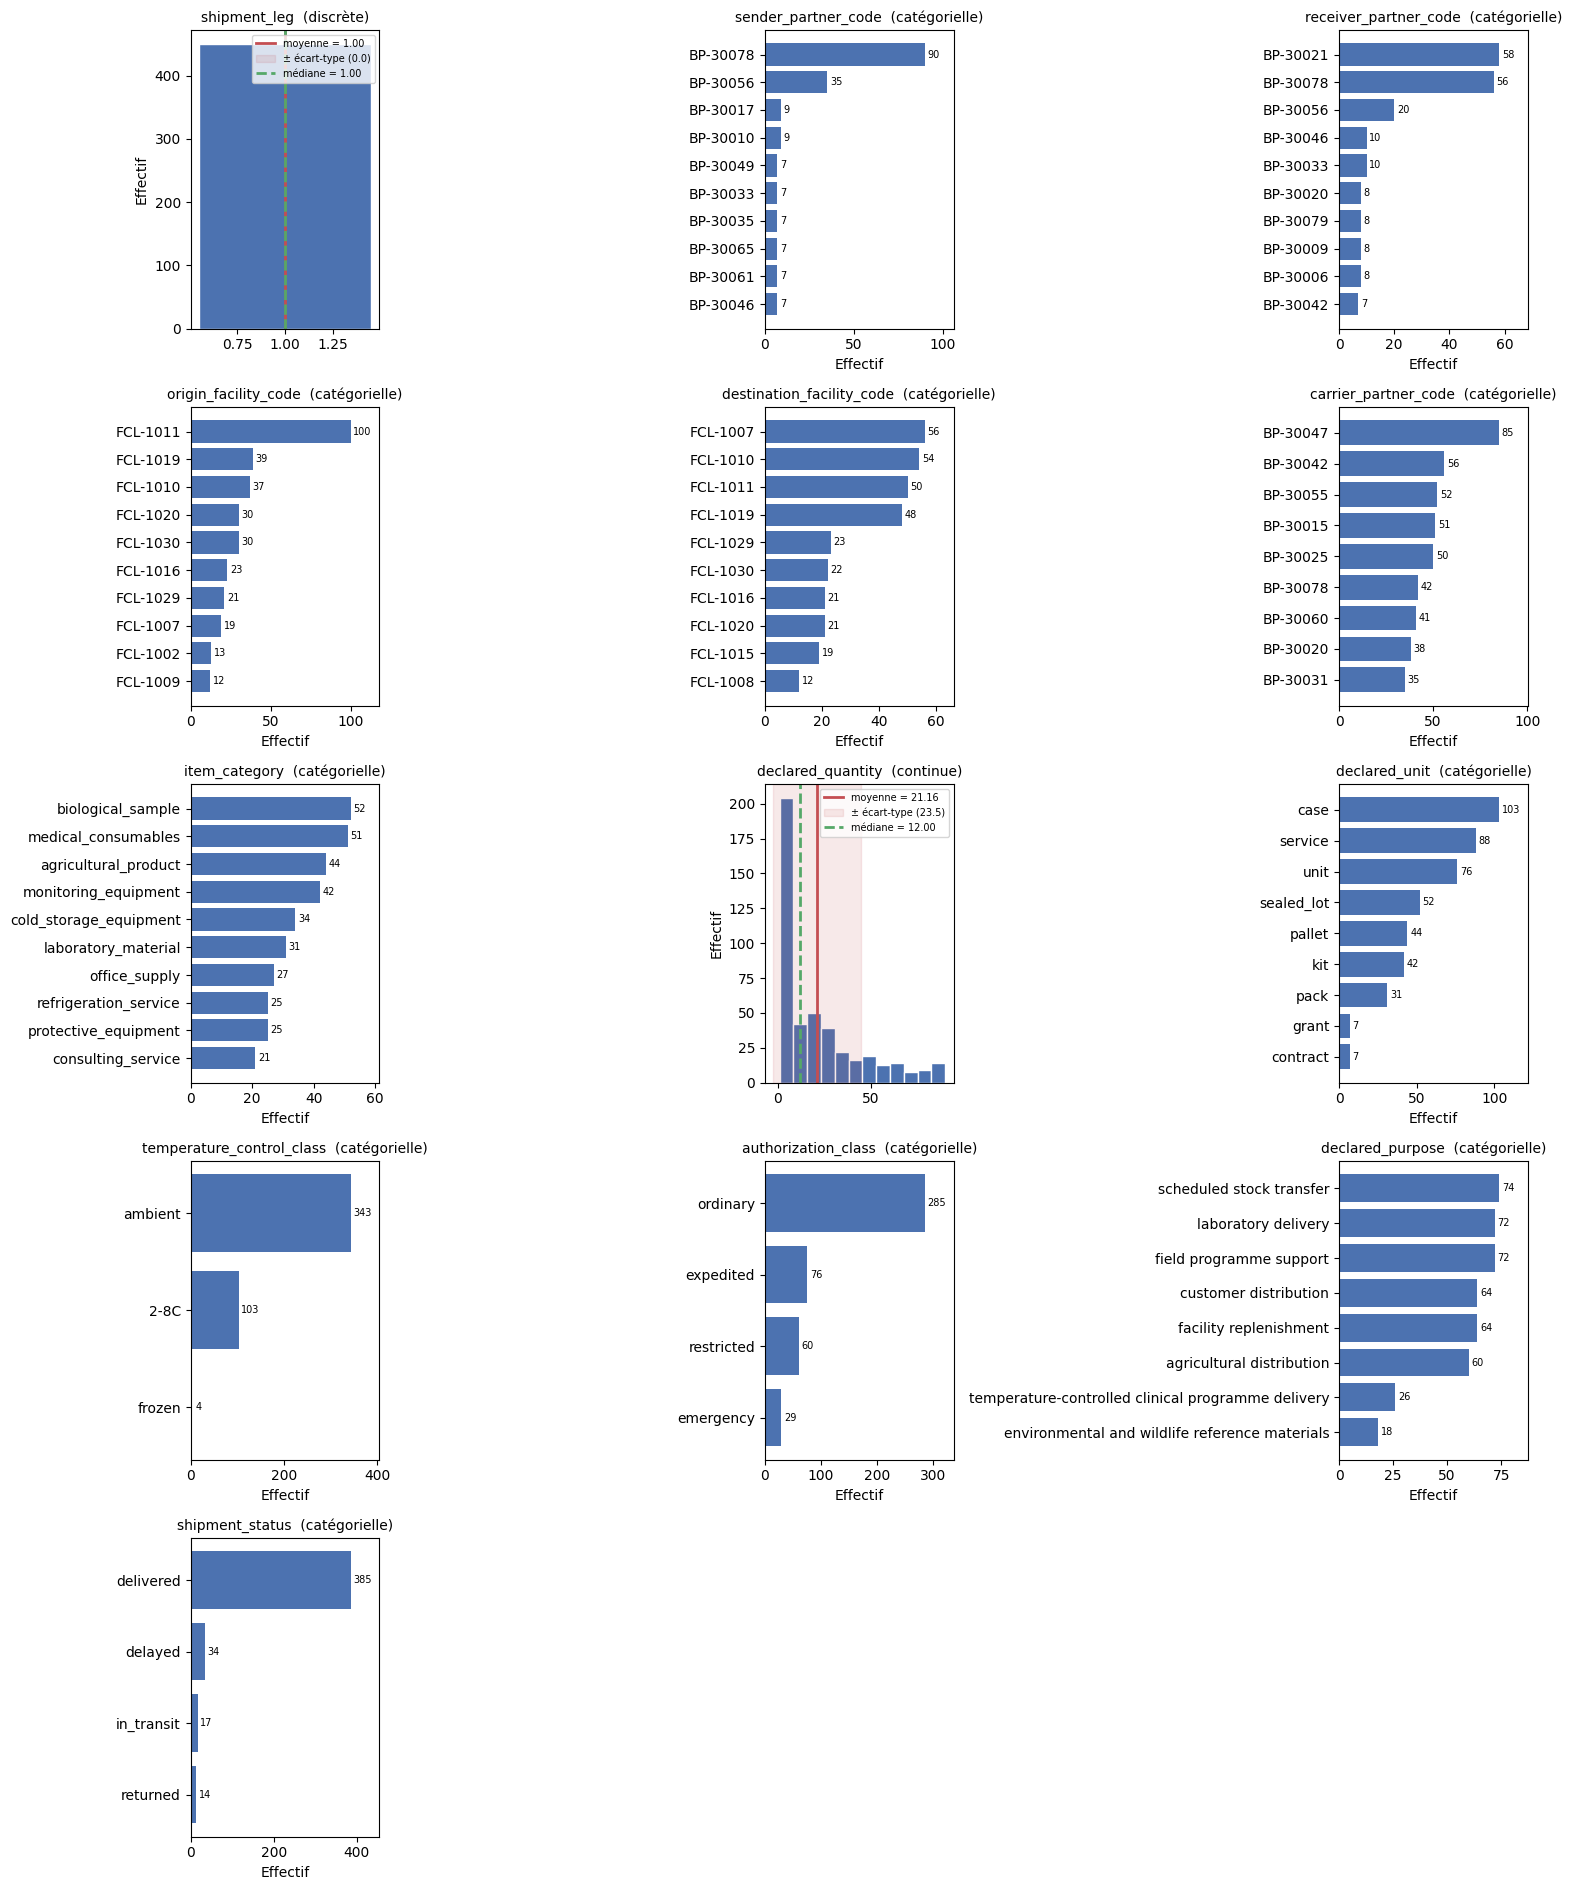


=== shipment_number  [identifiant] ===
  450 valeurs toutes (quasi) différentes : non analysée.

=== shipment_leg  [discrète] ===
  Effectif : 450  (manquants : 0, valeurs distinctes : 1)
  Moyenne ± écart-type : 1.000 ± 0.000
  Médiane [min ; Q1 - Q3 ; max] : 1.000 [1.000 ; 1.000 - 1.000 ; 1.000]
  Asymétrie : 0.00


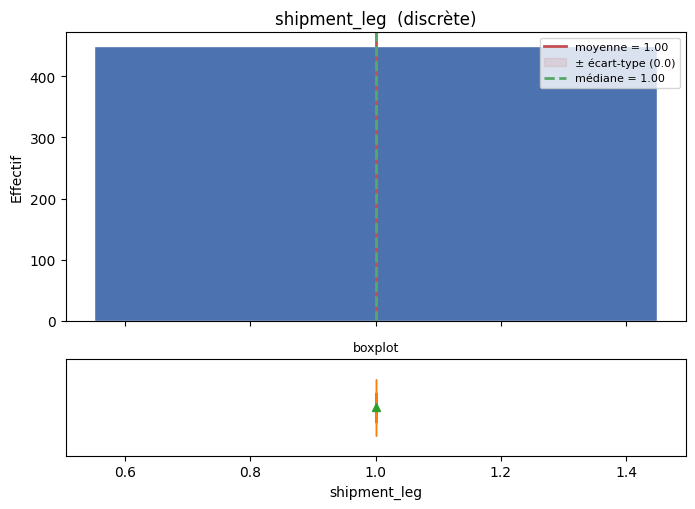


=== dispatch_time  [identifiant] ===
  441 valeurs toutes (quasi) différentes : non analysée.

=== arrival_time  [identifiant] ===
  426 valeurs toutes (quasi) différentes : non analysée.

=== sender_partner_code  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 72)
  Mode : BP-30078 (20.0 %)
                     effectif     %
sender_partner_code                
BP-30078                   90  20.0
BP-30056                   35   7.8
BP-30017                    9   2.0
BP-30010                    9   2.0
BP-30049                    7   1.6
BP-30033                    7   1.6
BP-30035                    7   1.6
BP-30065                    7   1.6
BP-30061                    7   1.6
BP-30046                    7   1.6
BP-30031                    7   1.6
BP-30080                    7   1.6
BP-30068                    7   1.6
BP-30030                    7   1.6
BP-30009                    7   1.6


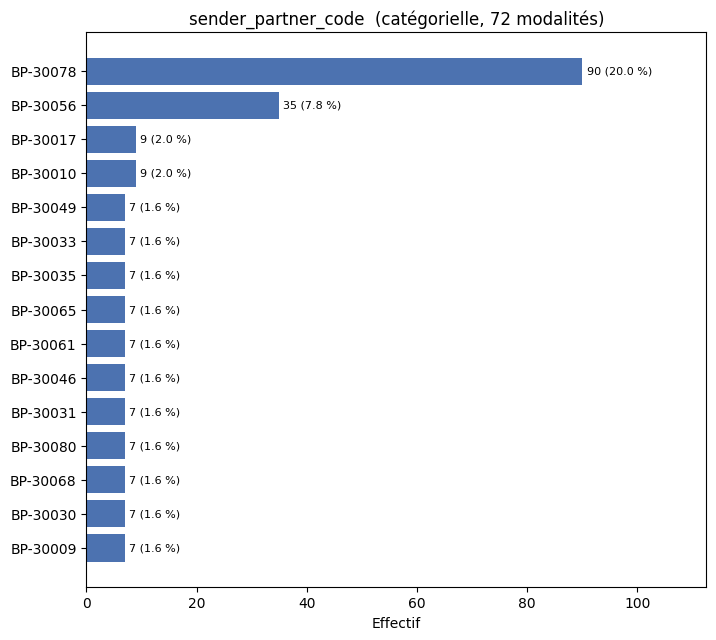


=== receiver_partner_code  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 71)
  Mode : BP-30021 (12.9 %)
                       effectif     %
receiver_partner_code                
BP-30021                     58  12.9
BP-30078                     56  12.4
BP-30056                     20   4.4
BP-30046                     10   2.2
BP-30033                     10   2.2
BP-30020                      8   1.8
BP-30079                      8   1.8
BP-30009                      8   1.8
BP-30006                      8   1.8
BP-30042                      7   1.6
BP-30041                      7   1.6
BP-30036                      7   1.6
BP-30044                      7   1.6
BP-30014                      7   1.6
BP-30018                      6   1.3


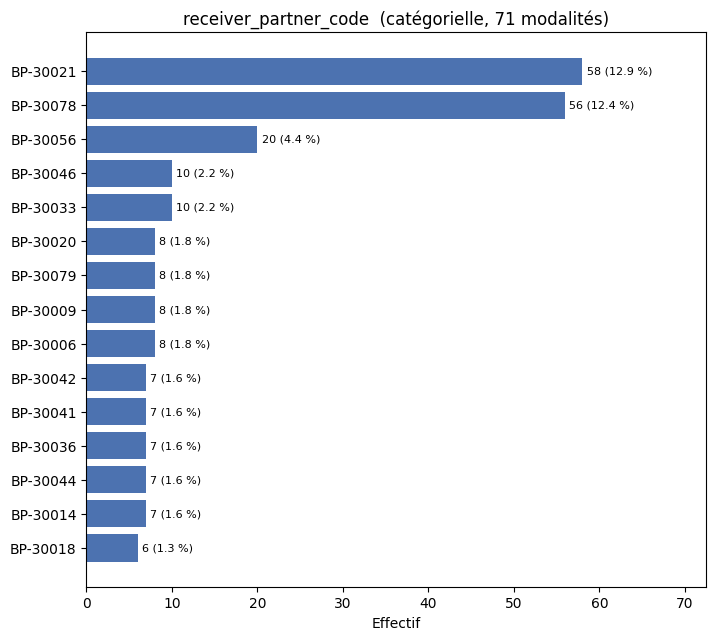


=== origin_facility_code  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 30)
  Mode : FCL-1011 (22.2 %)
                      effectif     %
origin_facility_code                
FCL-1011                   100  22.2
FCL-1019                    39   8.7
FCL-1010                    37   8.2
FCL-1020                    30   6.7
FCL-1030                    30   6.7
FCL-1016                    23   5.1
FCL-1029                    21   4.7
FCL-1007                    19   4.2
FCL-1002                    13   2.9
FCL-1009                    12   2.7
FCL-1014                    12   2.7
FCL-1015                    11   2.4
FCL-1003                    10   2.2
FCL-1023                    10   2.2
FCL-1008                    10   2.2


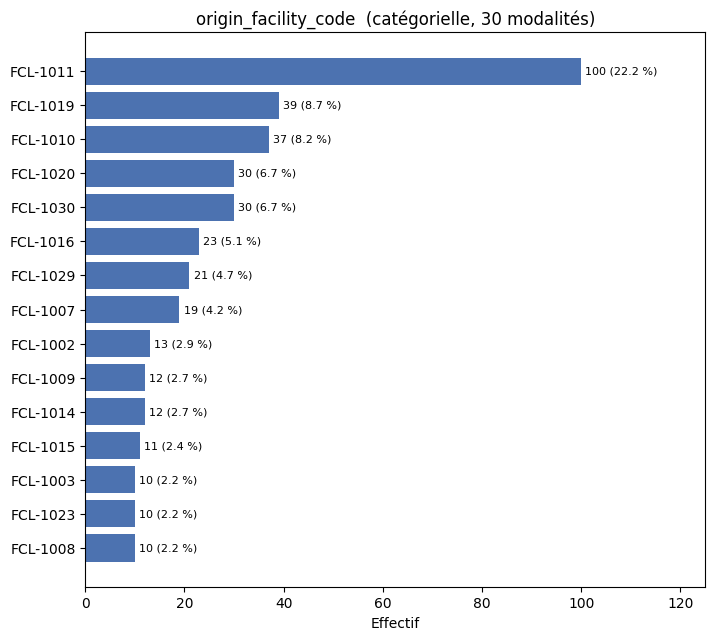


=== destination_facility_code  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 29)
  Mode : FCL-1007 (12.4 %)
                           effectif     %
destination_facility_code                
FCL-1007                         56  12.4
FCL-1010                         54  12.0
FCL-1011                         50  11.1
FCL-1019                         48  10.7
FCL-1029                         23   5.1
FCL-1030                         22   4.9
FCL-1016                         21   4.7
FCL-1020                         21   4.7
FCL-1015                         19   4.2
FCL-1008                         12   2.7
FCL-1003                         11   2.4
FCL-1013                         10   2.2
FCL-1023                         10   2.2
FCL-1024                         10   2.2
FCL-1014                          9   2.0


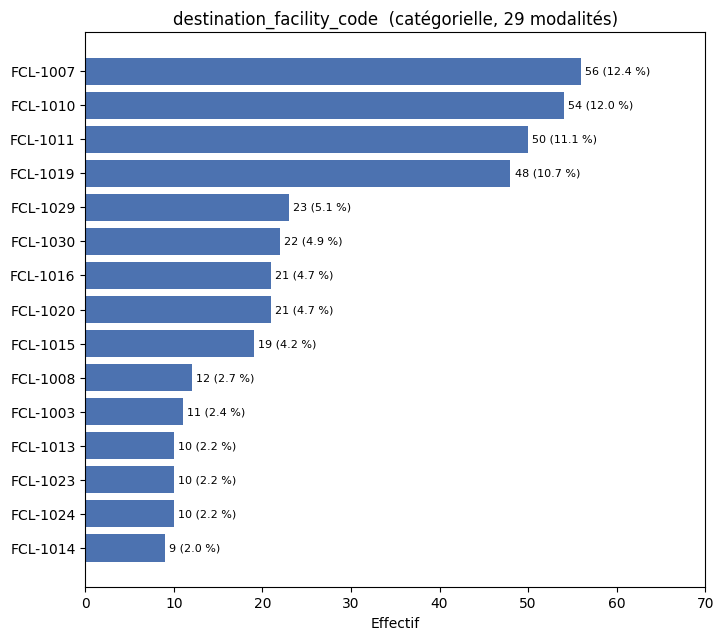


=== carrier_partner_code  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 9)
  Mode : BP-30047 (18.9 %)
                      effectif     %
carrier_partner_code                
BP-30047                    85  18.9
BP-30042                    56  12.4
BP-30055                    52  11.6
BP-30015                    51  11.3
BP-30025                    50  11.1
BP-30078                    42   9.3
BP-30060                    41   9.1
BP-30020                    38   8.4
BP-30031                    35   7.8


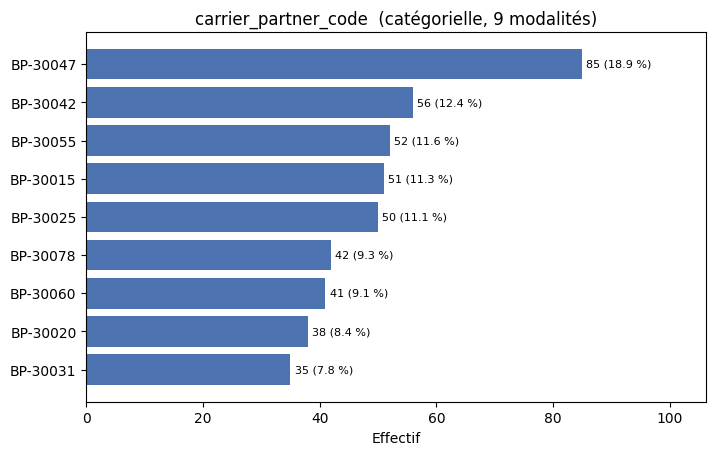


=== item_category  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 18)
  Mode : biological_sample (11.6 %)
                        effectif     %
item_category                         
biological_sample             52  11.6
medical_consumables           51  11.3
agricultural_product          44   9.8
monitoring_equipment          42   9.3
cold_storage_equipment        34   7.6
laboratory_material           31   6.9
office_supply                 27   6.0
refrigeration_service         25   5.6
protective_equipment          25   5.6
consulting_service            21   4.7
agricultural_equipment        19   4.2
transport_service             17   3.8
communication_service         15   3.3
medical_equipment             12   2.7
other                         11   2.4


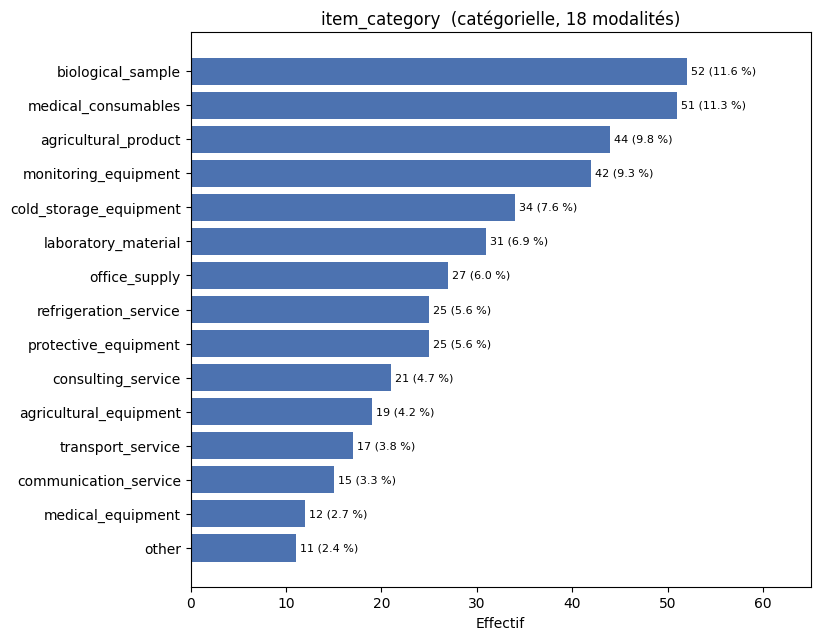


=== declared_quantity  [continue] ===
  Effectif : 450  (manquants : 0, valeurs distinctes : 79)
  Moyenne ± écart-type : 21.158 ± 23.548
  Médiane [min ; Q1 - Q3 ; max] : 12.000 [1.000 ; 2.000 - 31.000 ; 90.000]
  Asymétrie : 1.26


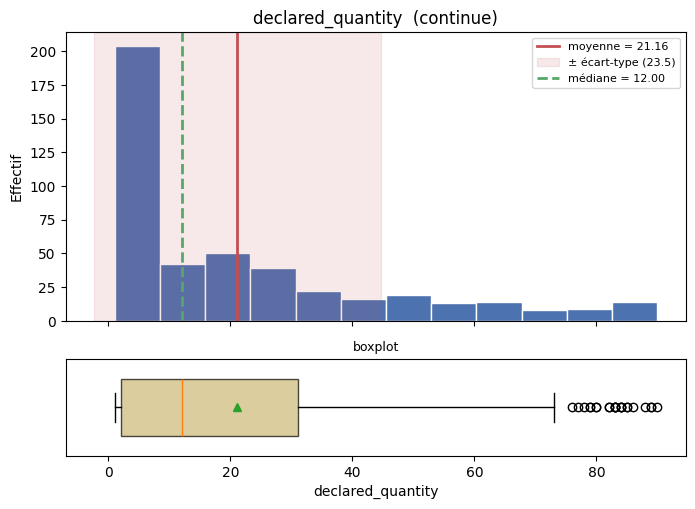


=== declared_unit  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 9)
  Mode : case (22.9 %)
               effectif     %
declared_unit                
case                103  22.9
service              88  19.6
unit                 76  16.9
sealed_lot           52  11.6
pallet               44   9.8
kit                  42   9.3
pack                 31   6.9
grant                 7   1.6
contract              7   1.6


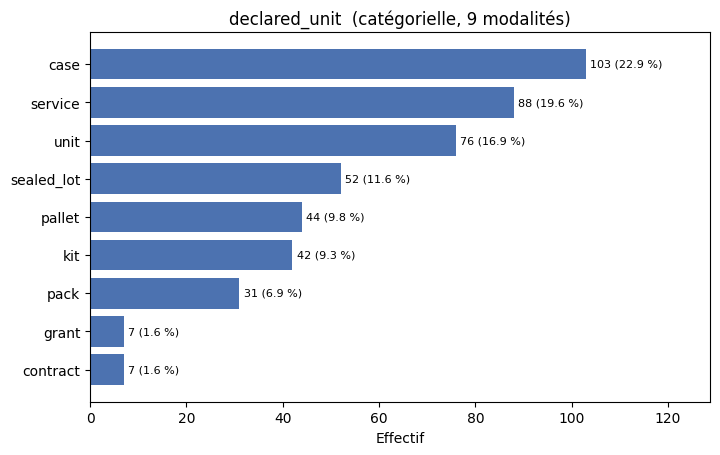


=== temperature_control_class  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 3)
  Mode : ambient (76.2 %)
                           effectif     %
temperature_control_class                
ambient                         343  76.2
2-8C                            103  22.9
frozen                            4   0.9


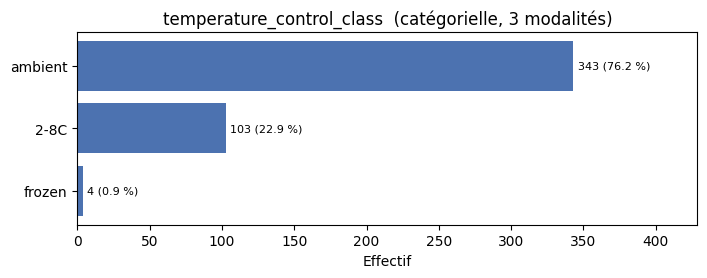


=== authorization_class  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 4)
  Mode : ordinary (63.3 %)
                     effectif     %
authorization_class                
ordinary                  285  63.3
expedited                  76  16.9
restricted                 60  13.3
emergency                  29   6.4


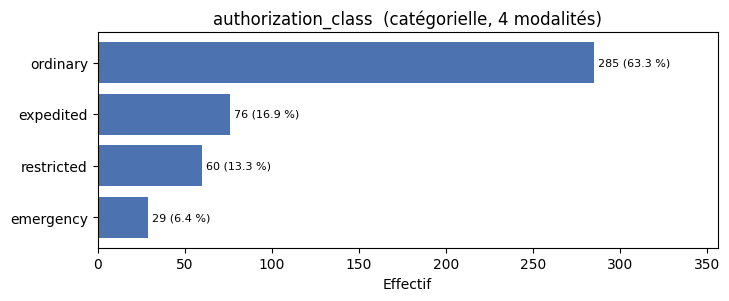


=== declared_purpose  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 8)
  Mode : scheduled stock transfer (16.4 %)
                                                    effectif     %
declared_purpose                                                  
scheduled stock transfer                                  74  16.4
laboratory delivery                                       72  16.0
field programme support                                   72  16.0
customer distribution                                     64  14.2
facility replenishment                                    64  14.2
agricultural distribution                                 60  13.3
temperature-controlled clinical programme delivery        26   5.8
environmental and wildlife reference materials            18   4.0


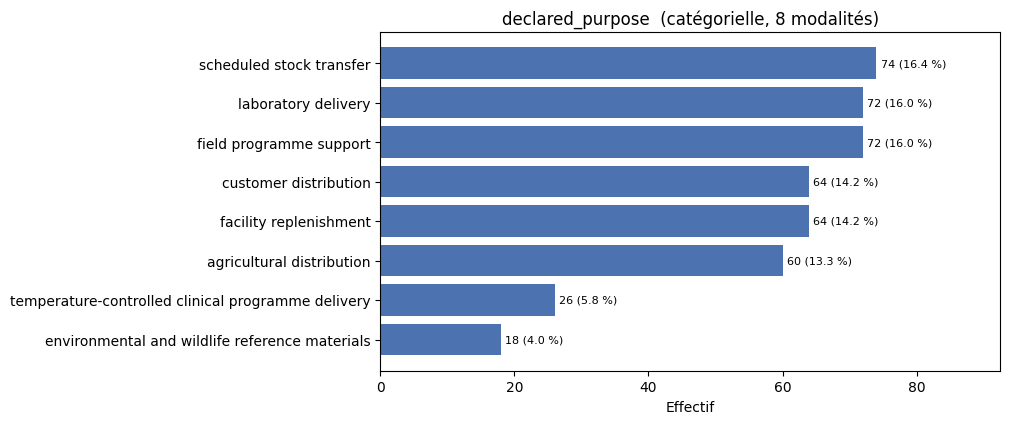


=== shipment_status  [catégorielle] ===
  Effectif : 450  (manquants : 0, modalités : 4)
  Mode : delivered (85.6 %)
                 effectif     %
shipment_status                
delivered             385  85.6
delayed                34   7.6
in_transit             17   3.8
returned               14   3.1


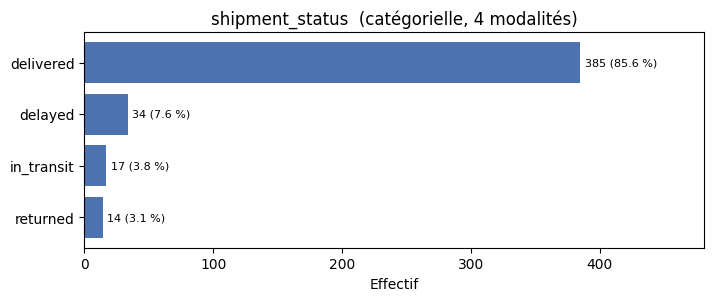

In [4]:
tracer_histogrammes(sh)
resume = analyser_variables(sh)

### Rapport d'analyse — analyse univariée

**1. Variables non exploitables**
- `shipment_number` est un identifiant (450 valeurs distinctes) et `shipment_leg` est **constante (= 1)** : aucune expédition n'est découpée en plusieurs segments, donc aucune chaîne de transport n'est traçable.
- `dispatch_time` (441 valeurs distinctes) et `arrival_time` (426) sont classées « identifiant » car quasi uniques : elles ne sont pas analysées, alors qu'elles contiennent de l'information temporelle. L'activité couvre **juillet 2014 à juin 2025** (calcul complémentaire), avec un pic en 2023 (73 expéditions).

**2. Acteurs et lieux : une forte concentration**
- Expéditeurs (72 modalités) : `BP-30078` en réalise **20 %** (90), puis `BP-30056` 7,8 % (35) ; aucun autre ne dépasse 2 %. Le même `BP-30078` est le 2ᵉ destinataire (12,4 %), derrière `BP-30021` (12,9 %).
- Sites d'origine : `FCL-1011` concentre **22,2 %** des départs (100). Dans les données, 90 de ces 100 expéditions sont envoyées par `BP-30078` (calcul complémentaire) : ce site semble être son centre logistique.
- Destinations plus équilibrées : quatre sites (`FCL-1007`, `1010`, `1011`, `1019`) reçoivent chacun 10,7 à 12,4 %.
- 9 transporteurs seulement ; `BP-30047` est le plus utilisé (**18,9 %**), les autres sont entre 7,8 % et 12,4 %.

**3. Nature des expéditions**
- 18 catégories d'articles, sans domination nette (`biological_sample` 11,6 %, `medical_consumables` 11,3 %). Neuf unités : `case` 22,9 %, `service` 19,6 %, `unit` 16,9 %.
- Température : **76,2 % `ambient`**, 22,9 % `2-8C`, seulement 4 `frozen` (0,9 %).
- Autorisation : `ordinary` 63,3 %, `expedited` 16,9 %, `restricted` 13,3 %, `emergency` 6,4 %.
- Motif : six motifs courants pesant 13 à 16 % chacun, et **deux motifs rares** : `temperature-controlled clinical programme delivery` (26, 5,8 %) et `environmental and wildlife reference materials` (**18, 4,0 %**).
- Statut : `delivered` **85,6 %**, `delayed` 7,6 % (34), `in_transit` 3,8 % (17), `returned` 3,1 % (14).

**4. Quantité déclarée**
- Moyenne 21,2 ± 23,5, médiane **12**, étendue 1 à 90, Q1–Q3 de 2 à 31, asymétrie **1,26** : distribution fortement étalée à droite, avec un pic sur les petites valeurs. Les services, subventions et contrats valent toujours 1 ; au total 106 lignes ont une quantité de 1 (calcul complémentaire).


---
## 3. Associations entre variables

### 3.1 Matrices de corrélation et V de Cramér



Colonnes constantes ou vides exclues : ['shipment_leg']
Matrice de spearman non tracée : Moins de 2 variables numériques/ordinales exploitables (trouvées : ['declared_quantity']). Exclues : ['shipment_number (identifiant)', 'dispatch_time (identifiant)', 'arrival_time (identifiant)', 'sender_partner_code (catégorielle)', 'receiver_partner_code (catégorielle)', 'origin_facility_code (catégorielle)', 'destination_facility_code (catégorielle)', 'carrier_partner_code (catégorielle)', 'item_category (catégorielle)', 'declared_unit (catégorielle)', 'temperature_control_class (catégorielle)', 'authorization_class (catégorielle)', 'declared_purpose (catégorielle)', 'shipment_status (catégorielle)']. Utilisez `ordres=` ou matrice_cramer().
Variables catégorielles utilisées (9) : ['origin_facility_code', 'destination_facility_code', 'carrier_partner_code', 'item_category', 'declared_unit', 'temperature_control_class', 'authorization_class', 'declared_purpose', 'shipment_status']
Variables exclue

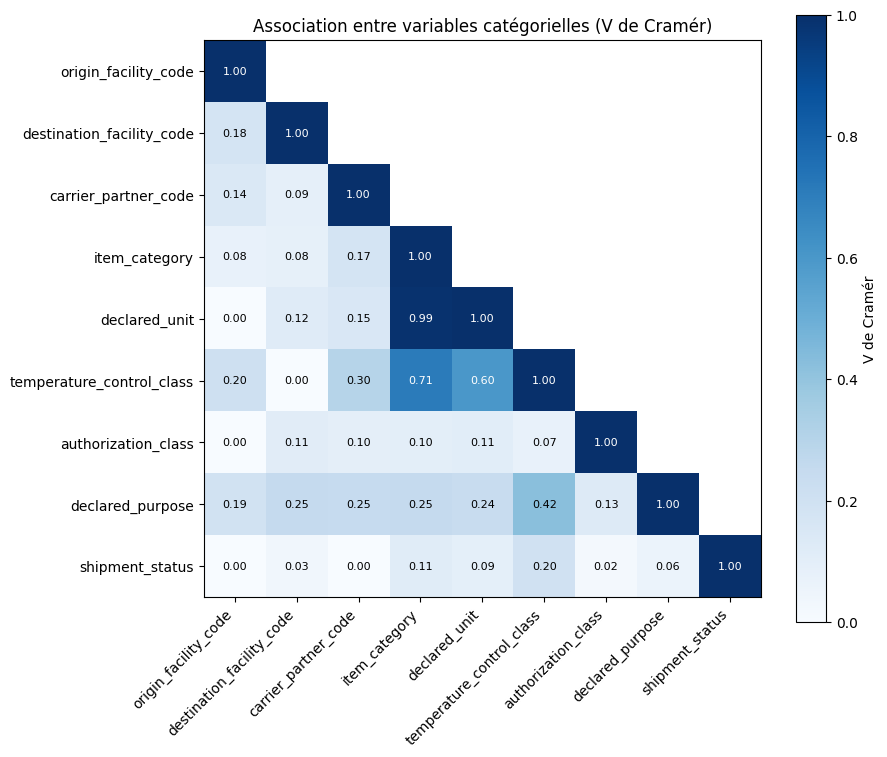


Paires avec |V de Cramér| >= 0.5 :
               variable_1    variable_2   valeur
            declared_unit item_category 0.989743
temperature_control_class item_category 0.710309
temperature_control_class declared_unit 0.601186


In [5]:
resultats = tracer_matrices(
    sh,
    ordres={"risk_class": ["low", "standard", "review", "elevated"],
            "partner_status": ["inactive", "active"]},
)

### Rapport d'analyse — associations


**Interprétation**
- **Redondance** : l'unité est quasiment déterminée par la catégorie (0,99). Les deux variables portent la même information, et garder les deux dans un modèle serait redondant.
- **La température structure les données** : elle découle de la catégorie. Dans les données, les 52 `biological_sample` et les 51 `medical_consumables` sont tous en `2-8C`, et les 4 `frozen` sont des `agricultural_product` (calcul complémentaire).
- **Lien température – statut (0,20)** : aucune des 103 expéditions `2-8C` n'est `delayed` (94 % livrées), alors que les 34 retards concernent tous des expéditions `ambient` (9,9 % d'entre elles). Les retards ne se distribuent donc pas au hasard.
- La classe d'autorisation et le statut sont presque indépendants du reste : ces variables ne sont pas prédites par les caractéristiques de l'expédition.



---
## 4. Recherche de patterns : itemsets fréquents

### 4.1 Enrichissement, extraction et profil d'un groupe


Le tableau est d'abord enrichi avec la région et les capacités de stockage du site de destination (table `erp_facilities`).

In [6]:
fa = lire_csv("../data/logistics/erp_facilities.csv")
sh = enrichir(sh, fa, cle="destination_facility_code", cle_autre="facility_code",
              colonnes=["region", "storage_capabilities"], prefixe="dest_")

res = detecter_patterns(sh, min_support=0.02)
F = res["itemsets"]
groupe = masque_itemset(res["transactions"], frozenset(F.itemset.iloc[0]), sh.index)
print(profiler_groupe(sh, groupe))

Transactions : 450 | colonnes utilisées : 14 | items distincts : 130
Colonnes exclues : ['shipment_number (identifiant)', 'shipment_leg (constante)', 'sender_partner_code (72 modalités > 30)', 'receiver_partner_code (71 modalités > 30)']

min_support = 0.020 (support absolu >= 9) -> 20509 itemsets fréquents, dont 7851 fermés
Répartition par taille : {1: 98, 2: 1102, 3: 3861, 4: 6084, 5: 5197, 6: 2702, 7: 1031, 8: 333, 9: 86, 10: 14, 11: 1}

--- Itemsets les plus FRÉQUENTS (taille >= 2) : décrivent surtout la majorité ---
                                                         itemset  support_abs  support_rel  lift
   shipment_status=delivered ∧ temperature_control_class=ambient          286        0.636 0.975
           dispatch_time_weekend=non ∧ shipment_status=delivered          273        0.607 1.003
            arrival_time_weekend=non ∧ shipment_status=delivered          256        0.569 1.014
        authorization_class=ordinary ∧ shipment_status=delivered          238        

### Rapport d'analyse — patterns

**Résultats**
- Base : **450 transactions**, 14 colonnes, **130 items** distincts. Exclues : `shipment_number`, `shipment_leg` (constante), expéditeur et destinataire (> 30 modalités). Les dates sont transformées en indicateurs week-end/semaine (`dispatch_time_weekend`, `arrival_time_weekend`) et la quantité en tranches.
- À `min_support = 2 %` : **20 509 itemsets fréquents**, dont seulement **7 851 fermés**. La taille va jusqu'à 11 items, avec un pic à 4 items (6 084 itemsets). Le nombre d'itemsets explose quand le seuil baisse : il faut se limiter aux itemsets fermés et les trier par lift.

**Itemsets les plus fréquents : le cas ordinaire**
- `delivered ∧ ambient` (286, 63,6 %), `non-week-end ∧ delivered` (273, 60,7 %), `ordinary ∧ delivered` (238, 52,9 %)… Tous ont un **lift entre 0,95 et 1,04** : ils sont fréquents parce que leurs éléments le sont, sans lien particulier entre eux.

**Itemsets les plus surprenants (fermés, lift ≥ 3, support ≥ 10)**
- Les 7 itemsets affichés contiennent tous **le transporteur `BP-30047`**, un envoi `delivered`, un départ hors week-end et une température **`2-8C`**. Ils se répartissent en deux familles :
  1. **Matériel de référence « environmental and wildlife »** : `biological_sample` en `sealed_lot`, souvent en petite quantité (1 à 4), vers des sites équipés de `ambient;secure_cage;2-8c;frozen`. Le groupe de base compte **18 expéditions** (4,0 %). Dans **15 d'entre elles, l'arrivée a lieu un week-end** (calcul complémentaire : 83 %, contre ≈ 32 % pour l'ensemble des expéditions) et **aucune n'est expédiée un week-end** (contre ≈ 29 %).
  2. **« Temperature-controlled clinical programme delivery »** : au départ de `FCL-1011`, vers des sites de capacité `2-8c;controlled_access` (dont `FCL-1010` et `FCL-1007`), soit en `biological_sample` / `sealed_lot` (12), soit en `medical_consumables` / `case` en grandes quantités (24 à 90).
- `BP-30047` assure 85 expéditions réparties sur 8 motifs, mais il est **le seul transporteur** des deux motifs sensibles ci-dessus (26 + 18 = 44 expéditions ; calcul complémentaire).

**Profil du groupe analysé (dernier tableau)**
- Le groupe profilé est l'itemset placé en première ligne de `F`, ici manifestement `shipment_status=delivered` (100 % de statut `delivered`, soit environ 385 lignes). Sa composition est quasi identique à l'ensemble (concentration comprise entre −0,02 et +0,02, sauf pour le statut qui définit le groupe) : ce profil **n'apporte aucune information**, puisqu'il décrit la majorité.

**Interprétation et réserves**
- Les lifts de 6 000 à 27 000 sont **gonflés mécaniquement** : sur un itemset de 8 à 10 items, le lift divise par le produit de nombreux petits supports. Ils indiquent que ces items n'apparaissent presque jamais l'un sans l'autre, pas une intensité mesurable ; on ne les compare pas entre itemsets de tailles différentes.
- Les deux familles décrivent un **flux spécialisé** (chaîne du froid, transporteur dédié, destinations équipées) cohérent sur le plan métier. Rien ne prouve une irrégularité : ce flux est isolé et mérite d'être confronté aux stocks, ajustements, commandes et réceptions des sites concernés.
- **Recommandation** : profiler les groupes réellement intéressants (par exemple les 18 expéditions « wildlife ») plutôt que `F.itemset.iloc[0]`.

---
## 5. Détection d'anomalies

### 5.1 Détection automatique (IQR, K-means, DBSCAN, ABOD)

*Objectif : repérer les lignes atypiques selon trois approches complémentaires : **univariée** (IQR, règle de Tukey), **multivariée par regroupement** (K-means : distance au centre ; DBSCAN : points « bruit ») et **basée sur les angles** (ABOD). Une ligne est retenue si au moins 2 méthodes multivariées l'identifient (`min_methodes=2`), avec une part de 3 % pour l'ABOD (`contamination=0.03`).*

Variables utilisées (3) : ['dispatch_time', 'arrival_time', 'declared_quantity']
Variables exclues : ['shipment_number (identifiant)', 'shipment_leg (constante)', 'sender_partner_code (catégorielle)', 'receiver_partner_code (catégorielle)', 'origin_facility_code (catégorielle)', 'destination_facility_code (catégorielle)', 'carrier_partner_code (catégorielle)', 'item_category (catégorielle)', 'declared_unit (catégorielle)', 'temperature_control_class (catégorielle)', 'authorization_class (catégorielle)', 'declared_purpose (catégorielle)', 'shipment_status (catégorielle)', 'dest_region (catégorielle)', 'dest_storage_capabilities (catégorielle)']

=== 1. Détection univariée (IQR) ===


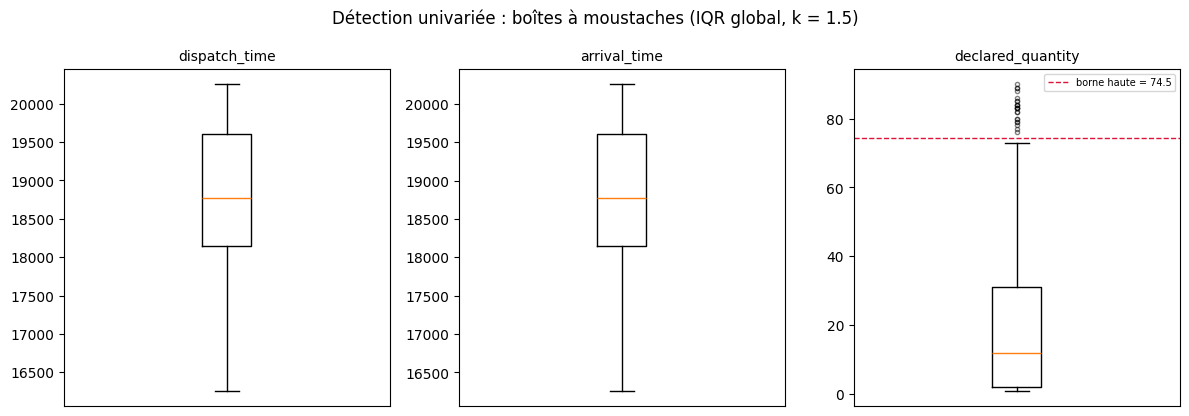

                         Q1        Q3   IQR  borne basse  borne haute  atypiques (IQR global)
variable                                                                                     
dispatch_time     1.814e+04  1.96e+04 1,464    1.594e+04     2.18e+04                       0
arrival_time      1.814e+04 1.961e+04 1,463    1.595e+04     2.18e+04                       0
declared_quantity         2        31    29        -41.5         74.5                      23
17 valeurs manquantes remplacées par la médiane de la colonne.

=== 2. Détection multivariée par regroupement ===


c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 556, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\TRETEC\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1038, 

K-means : k = 3 (silhouette 0.47), seuil de distance = 2.03 -> 12 atypiques
DBSCAN  : eps = 0.61, min_samples = 5 -> 2 groupes, 7 points bruit

=== 3. Angle-based Outlier Detection (ABOD) ===
ABOD    : FastABOD (k = 20), 3% d'ABOF les plus bas (seuil = 1.286) -> 14 atypiques


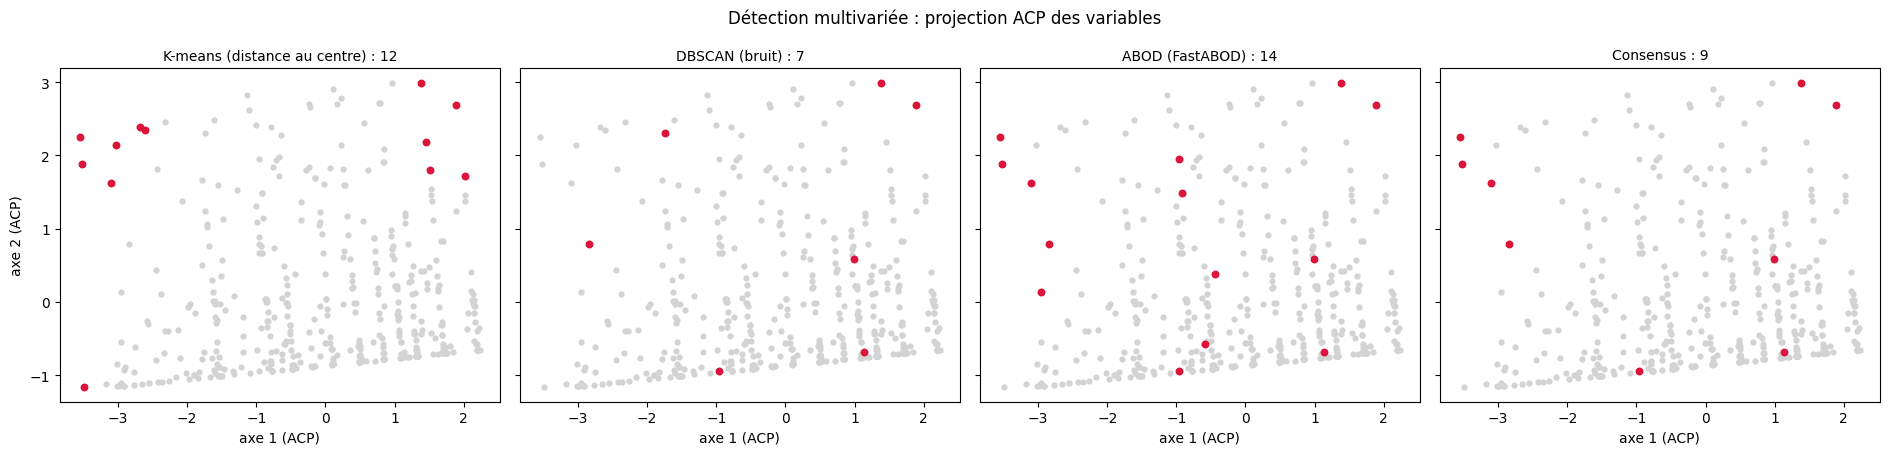


=== 4. Synthèse ===
Lignes signalées : {'out_kmeans': 12, 'out_dbscan': 7, 'out_abod': 14}
Nombre de méthodes d'accord : {0: 428, 1: 13, 2: 7, 3: 2}
Lignes en consensus (>= 2 méthodes) : 9
Lignes avec au moins une valeur hors IQR : 23


In [7]:
# Détection automatique des anomalies
resultat = detecter_anomalies(
    df=sh,
    show=True,              # évite d'afficher les graphiques
    inclure_dates=True,      # utilise aussi dispatch_time et arrival_time
    contamination=0.03,     # environ 3 % des lignes considérées comme atypiques
    min_methodes=2           # accord d'au moins 2 méthodes
)

# Lignes détectées comme anomalies
# display(resultat.anomalies)

# # Données complètes avec les indicateurs de détection
# display(resultat.donnees)

# # Variables réellement utilisées
# print("Variables analysées :", resultat.variables)

### Rapport d'analyse — anomalies

**1. Variables utilisées.** Seules 3 variables sont numériques : `dispatch_time` et `arrival_time` (converties en jours, option `inclure_dates=True`) et `declared_quantity`. Les variables catégorielles (transporteur, motif, etc.) ne sont pas prises en compte.

**2. Détection univariée (IQR)**
- `dispatch_time` et `arrival_time` : **0** valeur atypique.
- `declared_quantity` : Q1 = 2, Q3 = 31, IQR = 29, bornes [−41,5 ; 74,5] → **23 valeurs atypiques**. Dans les données, ce sont toutes des lignes en `case` (quantités de 75 à 90 : 13 `medical_consumables`, 6 `office_supply`, 4 `protective_equipment`) ; or en `case` la médiane est déjà de 54. Ce sont de **grosses commandes ordinaires**, pas des erreurs : l'IQR global confond ici hétérogénéité des unités et anomalie. La borne basse négative montre aussi qu'une quantité trop *faible* n'est jamais détectable.

**3. Valeurs manquantes.** *17 valeurs manquantes sont remplacées par la médiane* : ce sont les 17 `arrival_time = unknown` des expéditions `in_transit` (voir étape 1). L'imputation leur attribue une date d'arrivée « médiane » (mai 2021) sans rapport avec leur date de départ.

**4. Détection multivariée**
- **K-means** : k = 3 (silhouette **0,47**, groupes modérément séparés), seuil de distance 2,03 → **12** atypiques.
- **DBSCAN** : ε = 0,61, 2 groupes → **7** points « bruit ».
- **ABOD** (FastABOD, k = 20) → **14** atypiques ; ce nombre est fixé d'avance par `contamination` (3 % de 450 ≈ 14), il n'est pas découvert par la méthode.

**5. Synthèse des méthodes**
- Accord entre méthodes : aucune 428 lignes, une seule 13, deux 7, **trois 2**. Au total **9 lignes en consensus (2 %)**, et 23 lignes ont au moins une valeur hors IQR.
- Les graphiques de projection ACP montrent que ces lignes sont à la **périphérie du nuage**, surtout dans les coins les plus éloignés.


**Interprétation**
- **5 des 9 lignes** combinent une grande quantité (66 à 88, en `case`) et une date en début (2015) ou en fin de période (2024-2025) ; une 6ᵉ (`SHP-2016-00002`, quantité 46) est signalée par DBSCAN et ABOD. Ce sont des anomalies **statistiques**, à vérifier côté métier (grosse commande réelle ? saisie erronée ?).
- **3 des 9 lignes sont un artefact de l'imputation** : l'arrivée « médiane » (mai 2021) est incohérente avec un départ en 2017 ou 2025. Elles ne sont pas de vraies anomalies.
- Les dates sont réparties quasi uniformément sur 2014-2025 : seule la quantité est vraiment informative, la détection revient donc largement à « quantité élevée × date extrême ».
- **Aucune des méthodes ne signale le flux `BP-30047`** de l'étape 4 : ce pattern est de nature catégorielle et ne ressort pas dans des variables numériques. Les deux analyses sont **complémentaires**.



# Miner des graphes et des processus

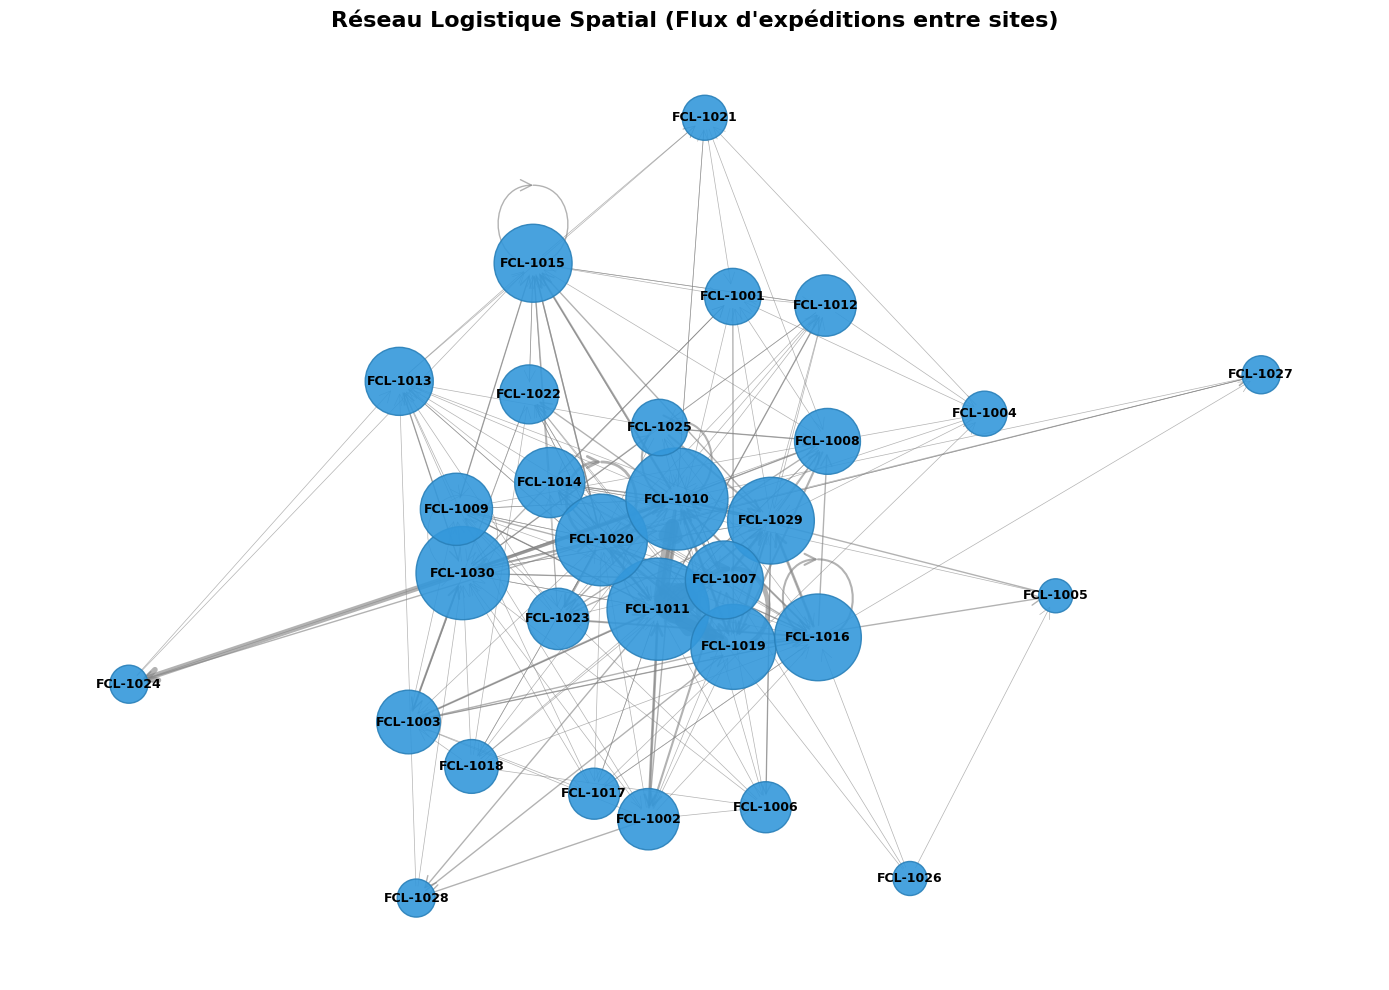

Top 3 Destinations (Hubs de réception) : [('FCL-1007', 56), ('FCL-1010', 54), ('FCL-1011', 50)]
Top 3 Origines (Hubs d'expédition) : [('FCL-1011', 100), ('FCL-1019', 39), ('FCL-1010', 37)]


In [8]:
import networkx as nx
import matplotlib.pyplot as plt

# 1. Chargement du fichier
# sh = pd.read_csv('shipments.csv')

# 2. Agrégation pour définir le poids des arcs (nombre d'expéditions entre origine et destination)
edges = sh.groupby(['origin_facility_code', 'destination_facility_code']).size().reset_index(name='weight')

# 3. Création du graphe orienté avec NetworkX
G = nx.from_pandas_edgelist(
    edges,
    source='origin_facility_code',
    target='destination_facility_code',
    edge_attr='weight',
    create_using=nx.DiGraph()
)

# 4. Visualisation du Réseau
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(G, k=0.6, seed=42) # k gère l'espacement entre les nœuds

# La taille des nœuds est proportionnelle à leur importance (degré sortant + entrant)
node_sizes = [G.degree(n) * 150 for n in G.nodes()]

nx.draw_networkx_nodes(G, pos, node_size=node_sizes, node_color='#3498db', edgecolors='#2980b9', alpha=0.9)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=20, edge_color='gray', alpha=0.6, 
                       width=[d['weight']*0.5 for u, v, d in G.edges(data=True)]) # Épaisseur = poids
nx.draw_networkx_labels(G, pos, font_size=9, font_weight='bold', font_color='black')

plt.title("Réseau Logistique Spatial (Flux d'expéditions entre sites)", fontsize=16, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()

# 5. Extraction des Hubs (Métriques)
in_degree = dict(G.in_degree(weight='weight'))
out_degree = dict(G.out_degree(weight='weight'))
print("Top 3 Destinations (Hubs de réception) :", sorted(in_degree.items(), key=lambda x: x[1], reverse=True)[:3])
print("Top 3 Origines (Hubs d'expédition) :", sorted(out_degree.items(), key=lambda x: x[1], reverse=True)[:3])

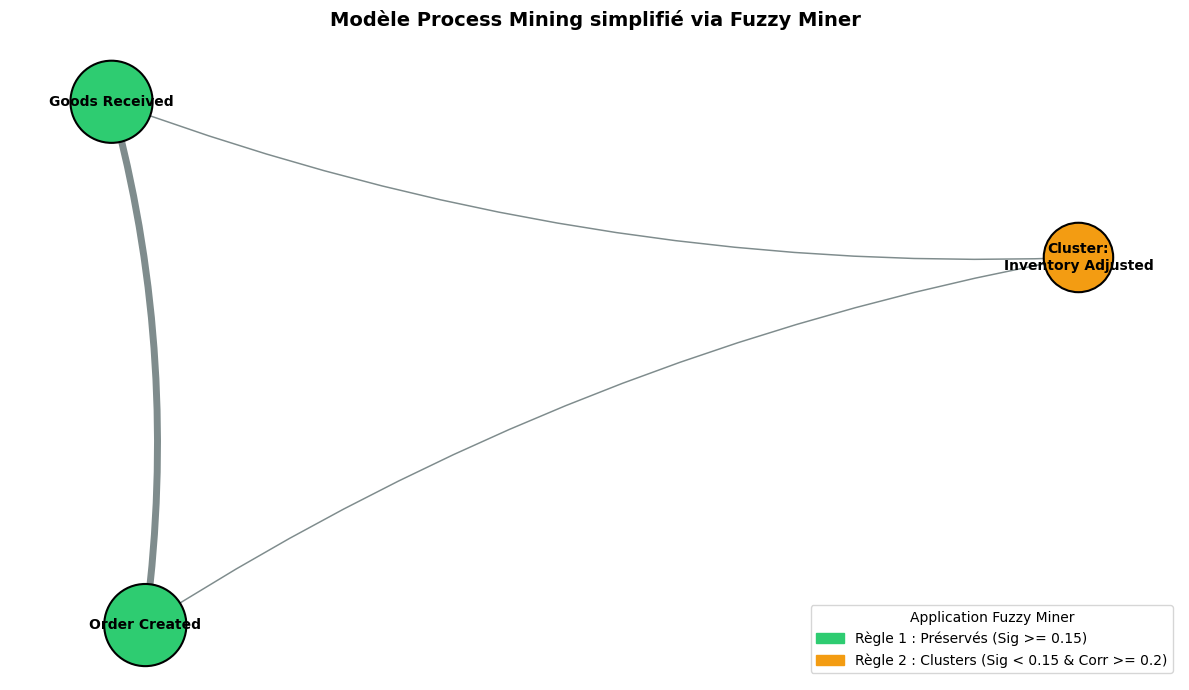

In [9]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# ==============================================================================
# 1. PRÉPARATION DES DONNÉES (Génération de l'Event Log ERP)
# ==============================================================================
# Chargement des fichiers ERP
df_po = pd.read_csv('../data/logistics/purchase_order_lines.csv')
df_gr = pd.read_csv('../data/logistics/goods_receipts.csv')
df_adj = pd.read_csv('../data/logistics/inventory_adjustments.csv')

# Extraction des événements
po_events = df_po[['purchase_order_number', 'order_date']].rename(columns={'purchase_order_number': 'case_id', 'order_date': 'timestamp'})
po_events['activity'] = 'Order Created'

gr_events = df_gr[['purchase_order_number', 'receipt_date']].rename(columns={'purchase_order_number': 'case_id', 'receipt_date': 'timestamp'})
gr_events['activity'] = 'Goods Received'

adj_merged = df_adj.merge(df_gr[['receipt_number', 'purchase_order_number']], left_on='related_receipt_number', right_on='receipt_number', how='inner')
adj_events = adj_merged[['purchase_order_number', 'adjustment_date']].rename(columns={'purchase_order_number': 'case_id', 'adjustment_date': 'timestamp'})
adj_events['activity'] = 'Inventory Adjusted'

# Concaténation et tri temporel
log = pd.concat([po_events, gr_events, adj_events])
log['timestamp'] = pd.to_datetime(log['timestamp'], format='mixed')
log = log.sort_values(by=['case_id', 'timestamp']).dropna()

# ==============================================================================
# 2. CALCUL DU GRAPHE DE BASE (Directly-Follows Graph)
# ==============================================================================
log['next_activity'] = log.groupby('case_id')['activity'].shift(-1)
dfg = log.dropna(subset=['next_activity']).groupby(['activity', 'next_activity']).size().reset_index(name='freq')

# ==============================================================================
# 3. MOTEUR FUZZY MINER : CALCUL DE LA SIGNIFIANCE ET CORRÉLATION
# ==============================================================================
# Fréquences maximales pour la normalisation
node_freq = log['activity'].value_counts().to_dict()
max_node_freq = max(node_freq.values())
max_edge_freq = dfg['freq'].max()

# 3.1. Calcul de la Signifiance (S) : Basée sur la fréquence relative
dfg['significance'] = dfg['freq'] / max_edge_freq
node_significance = {k: v / max_node_freq for k, v in node_freq.items()}

# 3.2. Calcul de la Corrélation (C) : Mesure de dépendance entre deux nœuds
def compute_correlation(row):
    act_a, act_b, freq_ab = row['activity'], row['next_activity'], row['freq']
    # Probabilité relative d'enchaînement (A->B sachant A, et A->B sachant B)
    return (freq_ab / node_freq[act_a] + freq_ab / node_freq[act_b]) / 2

dfg['correlation'] = dfg.apply(compute_correlation, axis=1)

# ==============================================================================
# 4. APPLICATION DES 3 RÈGLES DE L'ALGORITHME
# ==============================================================================
# Définition des seuils lambda
LAMBDA_SIG = 0.15   # Seuil de Signifiance
LAMBDA_CORR = 0.20  # Seuil de Corrélation

preserved_nodes = []
clustered_nodes = []
removed_nodes = []

for node, sig in node_significance.items():
    if sig >= LAMBDA_SIG:
        # RÈGLE 1 : Préservation des nœuds très signifiants
        preserved_nodes.append(node)
    else:
        # Recherche du degré de corrélation maximal pour ce nœud
        edges = dfg[(dfg['activity'] == node) | (dfg['next_activity'] == node)]
        max_corr = edges['correlation'].max() if not edges.empty else 0
        
        if max_corr >= LAMBDA_CORR:
            # RÈGLE 2 : Agrégation en Cluster (Faible signifiance MAIS Forte corrélation)
            clustered_nodes.append(node)
        else:
            # RÈGLE 3 : Suppression (Faible signifiance ET Faible corrélation)
            removed_nodes.append(node)

# ==============================================================================
# 5. VISUALISATION DU GRAPHE SIMPLIFIÉ
# ==============================================================================
fig, ax = plt.subplots(figsize=(12, 7))
G = nx.DiGraph()

# Ajout des nœuds selon leur catégorie (Règles 1 et 2 uniquement, on ignore la Règle 3)
for node in preserved_nodes:
    G.add_node(node, status='Preserved', color='#2ecc71', size=3500) # Vert
for node in clustered_nodes:
    G.add_node(f"Cluster:\n{node}", status='Clustered', color='#f39c12', size=2500) # Orange

# Filtrage et ajout des arcs 
for _, row in dfg.iterrows():
    act_a, act_b = row['activity'], row['next_activity']
    
    # Règle 3 sur les arcs : on ignore les liens impliquant un nœud supprimé
    if act_a in removed_nodes or act_b in removed_nodes:
        continue 
        
    node_a = f"Cluster:\n{act_a}" if act_a in clustered_nodes else act_a
    node_b = f"Cluster:\n{act_b}" if act_b in clustered_nodes else act_b
    
    # Règle sur les arcs (soit signifiant, soit corrélé)
    if row['significance'] >= LAMBDA_SIG or row['correlation'] >= LAMBDA_CORR:
        G.add_edge(node_a, node_b, weight=row['freq'], sig=row['significance'])

# Paramètres de dessin
pos = nx.spring_layout(G, seed=42)
colors = [G.nodes[n]['color'] for n in G.nodes()]
sizes = [G.nodes[n]['size'] for n in G.nodes()]

nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=sizes, edgecolors='black', linewidths=1.5)
nx.draw_networkx_labels(G, pos, ax=ax, font_weight='bold', font_size=10)

widths = [1 + 4 * G.edges[u, v]['sig'] for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, ax=ax, width=widths, arrowsize=20, edge_color='#7f8c8d', connectionstyle="arc3,rad=0.1")

# Légendes pour expliquer l'algo
pres_patch = mpatches.Patch(color='#2ecc71', label=f'Règle 1 : Préservés (Sig >= {LAMBDA_SIG})')
clust_patch = mpatches.Patch(color='#f39c12', label=f'Règle 2 : Clusters (Sig < {LAMBDA_SIG} & Corr >= {LAMBDA_CORR})')
# La règle 3 (Suppression) est invisible sur le graphe par définition
ax.legend(handles=[pres_patch, clust_patch], loc='lower right', title="Application Fuzzy Miner")
ax.set_title("Modèle Process Mining simplifié via Fuzzy Miner", fontsize=14, fontweight='bold', pad=15)
ax.axis('off')

plt.tight_layout()
plt.show()



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




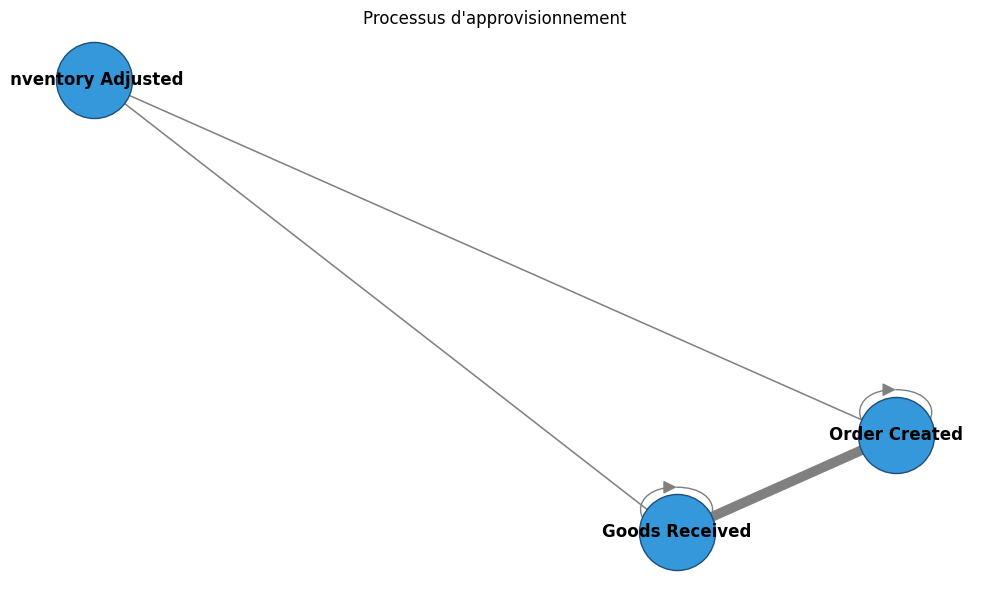

Réseau de Petri créé avec succès.


In [10]:
import pandas as pd
import pm4py

# 1. Chargement et préparation des événements depuis les fichiers ERP
df_po = pd.read_csv('../data/logistics/purchase_order_lines.csv')
df_gr = pd.read_csv('../data/logistics/goods_receipts.csv')
df_adj = pd.read_csv('../data/logistics/inventory_adjustments.csv')

po_events = df_po[['purchase_order_number', 'order_date']].rename(columns={'purchase_order_number': 'case_id', 'order_date': 'timestamp'})
po_events['activity'] = 'Order Created'

gr_events = df_gr[['purchase_order_number', 'receipt_date']].rename(columns={'purchase_order_number': 'case_id', 'receipt_date': 'timestamp'})
gr_events['activity'] = 'Goods Received'

adj_merged = df_adj.merge(df_gr[['receipt_number', 'purchase_order_number']], left_on='related_receipt_number', right_on='receipt_number', how='inner')
adj_events = adj_merged[['purchase_order_number', 'adjustment_date']].rename(columns={'purchase_order_number': 'case_id', 'adjustment_date': 'timestamp'})
adj_events['activity'] = 'Inventory Adjusted'

# Concaténation pour former le journal d'événements brut
log_df = pd.concat([po_events, gr_events, adj_events])
log_df['timestamp'] = pd.to_datetime(log_df['timestamp'], format='mixed')
log_df = log_df.sort_values(by=['case_id', 'timestamp']).dropna(subset=['case_id'])

# 2. Formatage standard exigé par pm4py
event_log = pm4py.format_dataframe(
    log_df,
    case_id='case_id',
    activity_key='activity',
    timestamp_key='timestamp'
)

# 3. Application de l'algorithme Heuristics Miner
# Les paramètres (thresholds) peuvent être ajustés pour filtrer plus ou moins le bruit
heu_net = pm4py.discover_heuristics_net(
    event_log, 
    dependency_threshold=0.5,  # Seuil de dépendance (0.0 à 1.0) pour accepter un lien
    and_threshold=0.65,        # Seuil pour détecter des activités concurrentes (AND)
    loop_two_threshold=0.5     # Seuil pour détecter les boucles de longueur 2 (A -> B -> A)
)

# 4. Visualisation sans Graphviz avec NetworkX
process_edges = (
    log_df.assign(next_activity=log_df.groupby('case_id')['activity'].shift(-1))
    .dropna(subset=['next_activity'])
    .groupby(['activity', 'next_activity'])
    .size()
    .reset_index(name='weight')
)

process_graph = nx.from_pandas_edgelist(
    process_edges,
    source='activity',
    target='next_activity',
    edge_attr='weight',
    create_using=nx.DiGraph()
)

plt.figure(figsize=(10, 6))
process_pos = nx.spring_layout(process_graph, seed=42)

nx.draw_networkx_nodes(
    process_graph,
    process_pos,
    node_color='#3498db',
    node_size=3000,
    edgecolors='#1f4e79',
)
nx.draw_networkx_edges(
    process_graph,
    process_pos,
    arrows=True,
    arrowsize=20,
    edge_color='gray',
    width=[
        1 + process_graph[u][v]['weight'] / 100
        for u, v in process_graph.edges()
    ],
)
nx.draw_networkx_labels(
    process_graph,
    process_pos,
    font_weight='bold',
)

plt.title("Processus d'approvisionnement")
plt.axis('off')
plt.tight_layout()
plt.show()

# Conversion facultative en réseau de Petri, sans appeler le visualiseur Graphviz
petri_net, initial_marking, final_marking = pm4py.convert_to_petri_net(heu_net)
print("Réseau de Petri créé avec succès.")

---
## 6. Analyse des flux spatiaux et temporels 
Les données ne fournissent pas nécessairement des coordonnées. On étudie
donc la dimension spatiale à travers le réseau orienté des sites d'origine
et de destination. Cette approche décrit les connexions logistiques,
mais ne remplace pas une carte géographique.

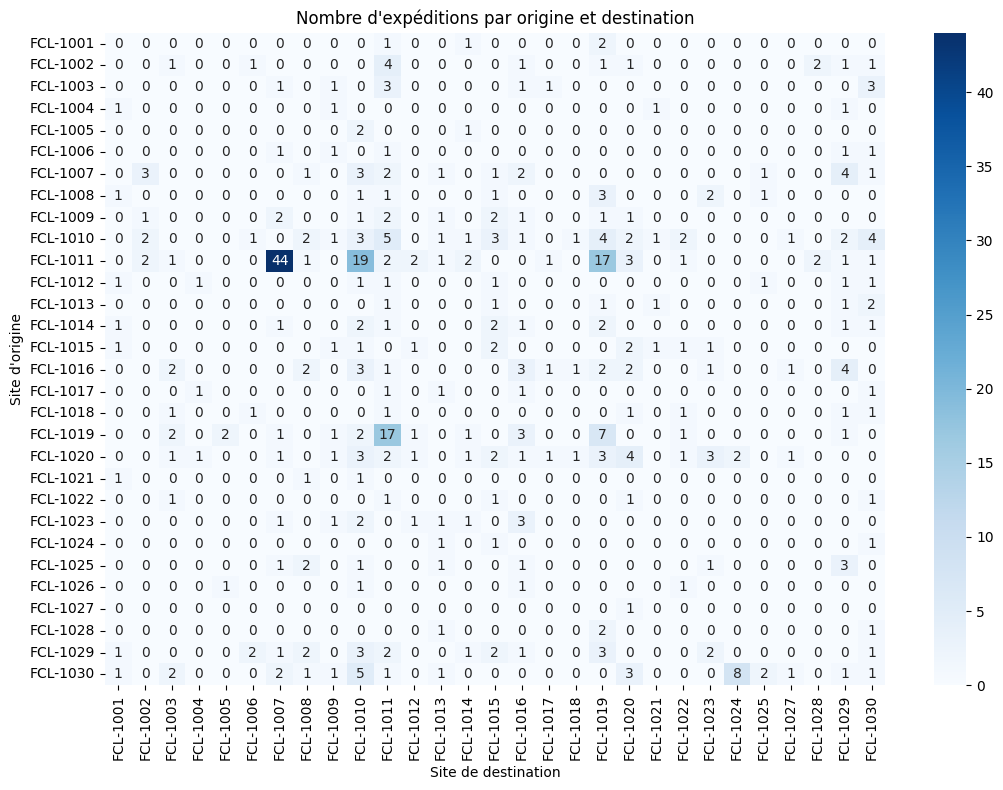

In [11]:
import seaborn as sns
import networkx as nx

sh_spatial = sh.copy()
sh_spatial["famille_flux"] = np.select(
    [
        sh_spatial["declared_purpose"].astype(str).str.contains("wildlife", case=False, na=False),
        sh_spatial["declared_purpose"].astype(str).str.contains("clinical", case=False, na=False)
    ],
    ["wildlife", "clinical"],
    default="autres"
)

# Matrice origine-destination : nombre d'expéditions entre chaque paire de sites.
matrice_flux = pd.pivot_table(
    sh_spatial, index="origin_facility_code",
    columns="destination_facility_code",
    values="shipment_number", aggfunc="count", fill_value=0
)
plt.figure(figsize=(11, 8))
sns.heatmap(matrice_flux, cmap="Blues", annot=True, fmt="g")
plt.title("Nombre d'expéditions par origine et destination")
plt.xlabel("Site de destination")
plt.ylabel("Site d'origine")
plt.tight_layout()
plt.show()

### 6.1 Comparaison des réseaux wildlife et clinical

On construit un graphe orienté pour chaque famille. Les nœuds sont les sites
et le poids des arcs correspond au nombre d'expéditions. La disposition
du graphe est algorithmique : elle ne représente pas les distances réelles.

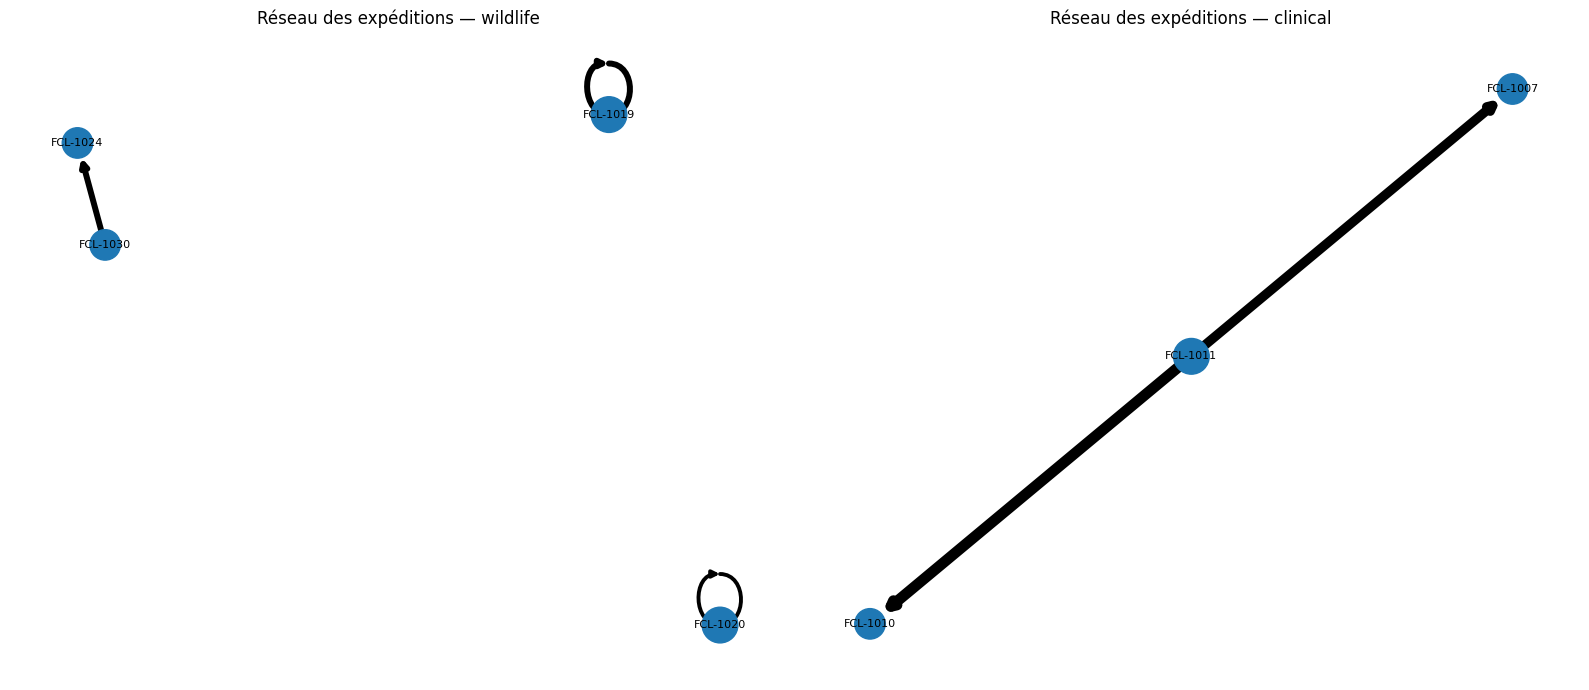


wildlife : 18 expéditions
Origines : {'FCL-1030': 7, 'FCL-1019': 7, 'FCL-1020': 4}
Destinations : {'FCL-1024': 7, 'FCL-1019': 7, 'FCL-1020': 4}

clinical : 26 expéditions
Origines : {'FCL-1011': 26}
Destinations : {'FCL-1010': 14, 'FCL-1007': 12}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, famille in zip(axes, ["wildlife", "clinical"]):
    sous = sh_spatial[sh_spatial["famille_flux"] == famille]
    arcs = (sous.groupby(["origin_facility_code", "destination_facility_code"])
            .size().reset_index(name="poids"))
    G_famille = nx.from_pandas_edgelist(
        arcs, source="origin_facility_code",
        target="destination_facility_code",
        edge_attr="poids", create_using=nx.DiGraph()
    )
    if G_famille.number_of_nodes() == 0:
        ax.set_title(f"Aucun flux {famille}")
        ax.axis("off")
        continue
    pos = nx.spring_layout(G_famille, seed=42)
    tailles = [300 + 180 * G_famille.degree(n) for n in G_famille.nodes()]
    largeurs = [0.8 + 0.5 * G_famille[u][v]["poids"]
                for u, v in G_famille.edges()]
    nx.draw_networkx(G_famille, pos, ax=ax, with_labels=True,
                     node_size=tailles, font_size=8,
                     arrows=True, width=largeurs)
    ax.set_title(f"Réseau des expéditions — {famille}")
    ax.axis("off")
plt.tight_layout()
plt.show()

for famille in ["wildlife", "clinical"]:
    sous = sh_spatial[sh_spatial["famille_flux"] == famille]
    print(f"\n{famille} : {len(sous)} expéditions")
    print("Origines :", sous["origin_facility_code"].value_counts().head(5).to_dict())
    print("Destinations :", sous["destination_facility_code"].value_counts().head(5).to_dict())

### 6.2 Évolution temporelle des expéditions

On agrège les expéditions par mois de départ et par famille déclarée.
L'objectif est de repérer des concentrations temporelles ou des périodes
où les flux spécialisés évoluent différemment.

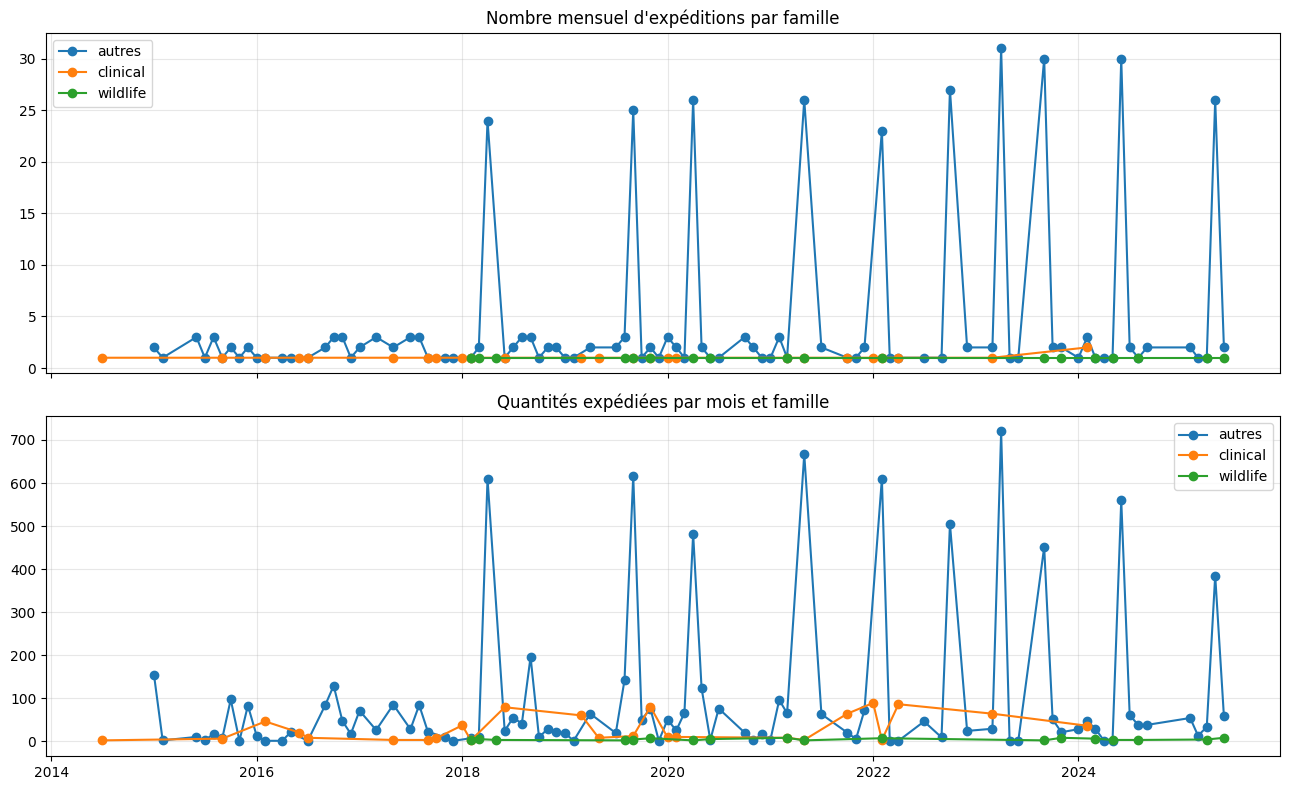

,mois,famille_flux,nb_expeditions,quantite
0,2014-07-01,clinical,1,2
1,2015-01-01,autres,2,155
2,2015-02-01,autres,1,2
3,2015-06-01,autres,3,10
4,2015-07-01,autres,1,2
5,2015-08-01,autres,3,17
6,2015-09-01,autres,1,7
7,2015-09-01,clinical,1,6
8,2015-10-01,autres,2,97
9,2015-11-01,autres,1,1


In [13]:
sh_temp = sh_spatial.copy()
sh_temp["dispatch_time"] = pd.to_datetime(sh_temp["dispatch_time"], errors="coerce")
sh_temp = sh_temp.dropna(subset=["dispatch_time"]).copy()
sh_temp["mois"] = sh_temp["dispatch_time"].dt.to_period("M").dt.to_timestamp()

mensuel_sh = (sh_temp.groupby(["mois", "famille_flux"])
              .agg(nb_expeditions=("shipment_number", "size"),
                   quantite=("declared_quantity", "sum"))
              .reset_index())

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for famille, g in mensuel_sh.groupby("famille_flux"):
    axes[0].plot(g.mois, g.nb_expeditions, marker="o", label=famille)
    axes[1].plot(g.mois, g.quantite, marker="o", label=famille)
axes[0].set_title("Nombre mensuel d'expéditions par famille")
axes[1].set_title("Quantités expédiées par mois et famille")
for ax in axes:
    ax.grid(alpha=.3)
    ax.legend()
plt.tight_layout()
plt.show()
display(mensuel_sh.head(15))

### 6.3 Délais de transport

Le délai est calculé entre `dispatch_time` et `arrival_time`.
Les valeurs textuelles telles que `unknown`, les dates invalides et les
délais négatifs sont exclus et comptabilisés séparément.

Dates de départ manquantes : 3
Dates d'arrivée manquantes : 20
Délais négatifs : 0


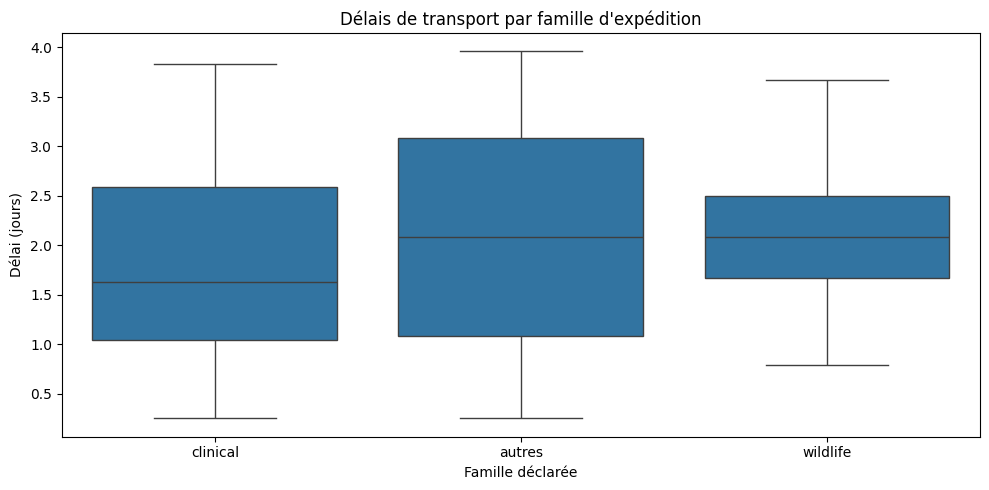

,count,mean,std,min,25%,50%,75%,max
famille_flux,,,,,,,,
autres,385.0,2.09,1.11,0.25,1.08,2.08,3.08,3.96
clinical,25.0,1.86,1.05,0.25,1.04,1.62,2.58,3.83
wildlife,17.0,2.09,0.75,0.79,1.67,2.08,2.50,3.67


In [14]:
sh_delais = sh_spatial.copy()
sh_delais["depart_dt"] = pd.to_datetime(sh_delais["dispatch_time"], errors="coerce")
sh_delais["arrivee_dt"] = pd.to_datetime(
    sh_delais["arrival_time"].replace("unknown", np.nan), errors="coerce"
)
sh_delais["delai_jours"] = (
    sh_delais["arrivee_dt"] - sh_delais["depart_dt"]
).dt.total_seconds() / 86400

print("Dates de départ manquantes :", int(sh_delais["depart_dt"].isna().sum()))
print("Dates d'arrivée manquantes :", int(sh_delais["arrivee_dt"].isna().sum()))
print("Délais négatifs :", int((sh_delais["delai_jours"] < 0).sum()))

delais_valides = sh_delais[
    sh_delais["delai_jours"].notna() & (sh_delais["delai_jours"] >= 0)
]
if not delais_valides.empty:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=delais_valides, x="famille_flux", y="delai_jours")
    plt.title("Délais de transport par famille d'expédition")
    plt.xlabel("Famille déclarée")
    plt.ylabel("Délai (jours)")
    plt.tight_layout()
    plt.show()
    display(delais_valides.groupby("famille_flux")["delai_jours"]
            .describe().round(2))
else:
    print("Aucun délai valide à comparer.")

## 7. Analyse textuelle des motifs d'expédition 

TF-IDF et les n-grams sont appliqués à `declared_purpose`.
Cette variable peut être composée de libellés courts : l'analyse est donc
principalement descriptive. Elle ne doit pas être présentée comme une
compréhension sémantique profonde des documents.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

textes_sh = sh["declared_purpose"].fillna("").astype(str)
tfidf_sh_vectorizer = TfidfVectorizer(
    lowercase=True, stop_words="english",
    ngram_range=(1, 2), min_df=2
)
try:
    X_sh_tfidf = tfidf_sh_vectorizer.fit_transform(textes_sh)
    scores_sh = np.asarray(X_sh_tfidf.sum(axis=0)).ravel()
    termes_sh = tfidf_sh_vectorizer.get_feature_names_out()
    top_sh = (pd.DataFrame({"terme": termes_sh, "score_tfidf": scores_sh})
              .sort_values("score_tfidf", ascending=False))
    display(top_sh.head(20))
except ValueError as e:
    print("TF-IDF non calculable :", e)

,terme,score_tfidf
9,distribution,59.257356
8,delivery,44.523186
16,laboratory,43.061544
17,laboratory delivery,43.061544
6,customer,39.658482
7,customer distribution,39.658482
0,agricultural,37.361828
1,agricultural distribution,37.361828
24,replenishment,36.950417
13,facility replenishment,36.950417


### 7.1 LDA exploratoire des motifs

LDA est pertinent surtout si le corpus contient plusieurs formulations
textuelles distinctes. Si `declared_purpose` ne contient que quelques
libellés répétés, le modèle risque simplement de retrouver ces catégories.

In [16]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

cv_sh = CountVectorizer(stop_words="english", ngram_range=(1, 2), min_df=2)
try:
    X_sh_count = cv_sh.fit_transform(textes_sh)
    vocab_sh = cv_sh.get_feature_names_out()
    if X_sh_count.shape[0] >= 10 and X_sh_count.shape[1] >= 3:
        lda_sh = LatentDirichletAllocation(
            n_components=min(3, X_sh_count.shape[1]),
            random_state=42, max_iter=20
        )
        distrib_sh = lda_sh.fit_transform(X_sh_count)
        for k, composante in enumerate(lda_sh.components_):
            ids = composante.argsort()[-8:][::-1]
            print(f"Topic {k+1} : " + ", ".join(vocab_sh[ids]))
        sh_topics = sh_spatial.copy()
        sh_topics["topic_lda"] = distrib_sh.argmax(axis=1)
        display(pd.crosstab(sh_topics["topic_lda"], sh_topics["famille_flux"],
                            normalize="index").round(2))
    else:
        print("Corpus trop petit ou vocabulaire trop réduit pour LDA.")
except ValueError as e:
    print("LDA non calculable :", e)

Topic 1 : facility replenishment, facility, replenishment, agricultural, agricultural distribution, distribution, delivery, field
Topic 2 : distribution, delivery, laboratory, laboratory delivery, customer distribution, customer, wildlife reference, materials
Topic 3 : programme, stock transfer, transfer, stock, scheduled, scheduled stock, support, field


famille_flux,autres,clinical,wildlife
topic_lda,,,
0,1.00,0.00,0.00
1,0.88,0.00,0.12
2,0.89,0.11,0.00


## Synthèse — Organisation des flux logistiques spécialisés

L'analyse des expéditions révèle deux flux particuliers qui se distinguent des opérations ordinaires.

Le premier correspond au motif `temperature-controlled clinical programme delivery`. Il regroupe **26 expéditions**, effectuées depuis le site `FCL-1011` vers les sites `FCL-1010` et `FCL-1007`. Ces expéditions concernent des échantillons biologiques et des consommables médicaux nécessitant des conditions de stockage contrôlées.

Le second correspond au motif `environmental and wildlife reference materials`. Il regroupe **18 expéditions**, principalement associées aux sites `FCL-1030`, `FCL-1019` et `FCL-1020`. Ces expéditions concernent notamment des échantillons biologiques transportés en `sealed_lot`.

Les deux groupes partagent plusieurs caractéristiques :
- Le transporteur est systématiquement `BP-30047`.
- Les expéditions sont réalisées hors week-end.
- Les expéditions sont associées à une température contrôlée de `2-8C`.
- Le statut des expéditions est majoritairement `delivered`.

Le motif wildlife présente également une particularité temporelle : **15 des 18 expéditions arrivent pendant le week-end**, alors qu'aucune n'est expédiée pendant le week-end.

Le recoupement avec les achats renforce cette observation : les 26 expéditions cliniques correspondent aux 26 commandes du centre `Clinical Programmes`, tandis que les 18 expéditions wildlife correspondent aux 18 commandes `Field Operations`.

Enfin, le partenaire `BP-30078` est associé à ces commandes et joue également un rôle important dans les expéditions. Le transporteur `BP-30047`, quant à lui, assure exclusivement les deux flux spécialisés identifiés.

